# WikiText  Dataset

Extrapolated optimal LR for width=32: 9.9529e-03
Extrapolated optimal LR for width=48: 7.2559e-03
Extrapolated optimal LR for width=64: 5.7983e-03
Extrapolated optimal LR for width=80: 4.8726e-03
Extrapolated optimal LR for width=96: 4.2271e-03
Extrapolated optimal LR for width=104: 3.9714e-03
Extrapolated optimal LR for width=128: 3.3779e-03
Extrapolated optimal LR for width=160: 2.8386e-03
Extrapolated optimal LR for width=192: 2.4626e-03
Extrapolated optimal LR for width=224: 2.1837e-03
Extrapolated optimal LR for width=256: 1.9679e-03
Fit parameters: A=1.4832e-01, B=-0.7795
Extrapolated optimal LR for width=256: 1.9679e-03


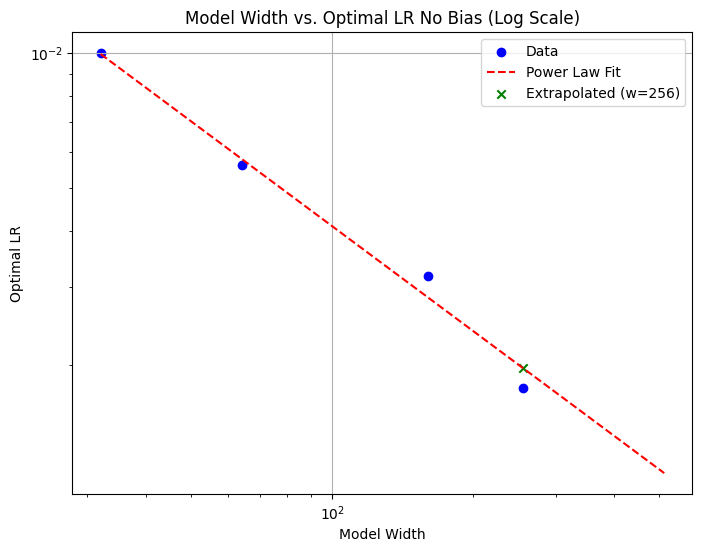

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Data
model_width = np.array([32, 64, 160, 256])
optimal_lr = np.array([10**-2, 10**-2.25, 10**-2.5, 10**-2.75])

# Fit function: assume a power law for lr = A * width ^ B
def power_law(width, A, B):
    return A * width ** B

# Fit in log space for more stability
popt, pcov = curve_fit(power_law, model_width, optimal_lr, p0=[1e-3, 0])

# Extrapolate to width=hidden_dims, print each
hidden_dims = [32, 48,  64, 80, 96, 104, 128, 160,192, 224, 256]
extrapolated_lrs = [power_law(w, *popt) for w in hidden_dims]
for w, lr in zip(hidden_dims, extrapolated_lrs):
    print(f"Extrapolated optimal LR for width={w}: {lr:.4e}")

print(f"Fit parameters: A={popt[0]:.4e}, B={popt[1]:.4f}")

# For plotting, highlight one width (e.g., last in hidden_dims)
highlight_idx = -1  # pick last one
highlight_dim = hidden_dims[highlight_idx]
highlight_lr = extrapolated_lrs[highlight_idx]
print(f"Extrapolated optimal LR for width={highlight_dim}: {highlight_lr:.4e}")

# Plot
plt.figure(figsize=(8,6))
plt.scatter(model_width, optimal_lr, label='Data', color='blue')
widths_for_line = np.linspace(min(model_width), 512, 200)
plt.plot(widths_for_line, power_law(widths_for_line, *popt), 'r--', label='Power Law Fit')
plt.scatter([highlight_dim], [highlight_lr], color='green', marker='x', label=f'Extrapolated (w={highlight_dim})')
plt.yscale('log')
plt.xscale('log')
plt.xlabel('Model Width')
plt.ylabel('Optimal LR')
plt.title('Model Width vs. Optimal LR No Bias (Log Scale)')
plt.legend()
plt.grid(True)
plt.show()

# OpenWebText

# C4

# The Pile